# TC5061 — Modelo base: fatiga del día siguiente y hábitos nocturnos

Versión de exploración: describe el dataset, lo explora y revisa su calidad. El entrenamiento, la evaluación y el registro en MLflow están en `train.py`.

**Pregunta.** Predecir `next_day_fatigue_score`, un puntaje continuo de fatiga al día siguiente en escala de 1 a 10.

**De dónde sale la pregunta.** El dataset de Kaggle propone entrenar un regresor con variables de conducta (cafeína, aplicación y tiempo de pantalla) y dejar fuera las salidas fisiológicas del sueño. Este notebook sigue esa restricción. El objetivo de la actividad es un baseline reproducible, no el mejor modelo posible.

**Datos.** [Sleep Debt & Screen Time: Late Night Phone Habits](https://www.kaggle.com/datasets/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits) (Samar Talwar). Simulación de hábitos nocturnos de 8,500 personas. Licencia CC BY-SA 4.0. El archivo se descarga con `kagglehub` para que el notebook se pueda volver a correr.

## 1. Carga y descripción del dataset

Primero se baja el CSV y se revisa tamaño, tipos y significado de cada columna. Sin eso, las gráficas y el modelo no tienen contexto.

In [1]:
# Descarga el CSV (usa la copia en caché si ya existe) y carga las librerías del flujo.
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

from pathlib import Path
import hashlib

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

dataset_dir = Path(kagglehub.dataset_download(
    "samartalwar/sleep-debt-and-screen-time-late-night-phone-habits"
))
csv_path = dataset_dir / "bedtime_screentime_sleep_debt.csv"
df = pd.read_csv(csv_path)

print("archivo:", csv_path.name)
print("registros:", df.shape[0])
print("variables:", df.shape[1])

archivo: bedtime_screentime_sleep_debt.csv
registros: 8500
variables: 18


El archivo trae **8,500 filas y 18 columnas**: una fila por persona. No hay una serie de tiempo; cada registro es un corte transversal de hábitos de una noche y el resultado de la mañana siguiente.

In [2]:
# Muestra tipos, un ejemplo y el diccionario de columnas para fijar qué mide cada variable.
diccionario = pd.DataFrame({
    "columna": [
        "user_id", "age", "gender", "occupation_type", "chronotype",
        "bedtime_phone_minutes", "primary_bedtime_app", "screen_brightness_pct",
        "blue_light_filter_active", "caffeine_post_5pm_mg", "physical_activity_min",
        "sleep_latency_min", "total_sleep_hours", "deep_sleep_pct", "rem_sleep_pct",
        "morning_alarm_snoozes", "next_day_fatigue_score", "sleep_debt_category",
    ],
    "tipo_en_archivo": [str(df[c].dtype) for c in [
        "user_id", "age", "gender", "occupation_type", "chronotype",
        "bedtime_phone_minutes", "primary_bedtime_app", "screen_brightness_pct",
        "blue_light_filter_active", "caffeine_post_5pm_mg", "physical_activity_min",
        "sleep_latency_min", "total_sleep_hours", "deep_sleep_pct", "rem_sleep_pct",
        "morning_alarm_snoozes", "next_day_fatigue_score", "sleep_debt_category",
    ]],
    "rol": [
        "id", "contexto", "contexto", "contexto", "contexto",
        "conducta", "conducta", "conducta", "conducta", "conducta", "conducta",
        "fisiológica", "fisiológica", "fisiológica", "fisiológica",
        "resultado de la mañana", "objetivo", "otra etiqueta",
    ],
    "significado": [
        "Identificador de la persona",
        "Edad en años",
        "Género reportado",
        "Tipo de ocupación",
        "Cronotipo: Morning Lark, Intermediate o Night Owl",
        "Minutos de celular en la cama antes de dormir",
        "Aplicación más usada en esa sesión",
        "Brillo de pantalla, de 10% a 100%",
        "Filtro de luz azul: 1 activo, 0 inactivo",
        "Cafeína después de las 17:00, en miligramos",
        "Minutos de ejercicio ese día",
        "Minutos para quedarse dormido",
        "Horas de sueño antes de la alarma",
        "Porcentaje de sueño profundo",
        "Porcentaje de sueño REM",
        "Veces que pospuso la alarma",
        "Fatiga del día siguiente, de 1.0 a 10.0",
        "Categoría de deuda de sueño (no se usa en este modelo)",
    ],
})
display(diccionario)
print()
display(df.head(3))

,columna,tipo_en_archivo,rol,significado
0,user_id,str,id,Identificador de la persona
1,age,int64,contexto,Edad en años
2,gender,str,contexto,Género reportado
3,occupation_type,str,contexto,Tipo de ocupación
4,chronotype,str,contexto,"Cronotipo: Morning Lark, Intermediate o Night Owl"
5,bedtime_phone_minutes,int64,conducta,Minutos de celular en la cama antes de dormir
6,primary_bedtime_app,str,conducta,Aplicación más usada en esa sesión
7,screen_brightness_pct,int64,conducta,"Brillo de pantalla, de 10% a 100%"
8,blue_light_filter_active,int64,conducta,"Filtro de luz azul: 1 activo, 0 inactivo"
9,caffeine_post_5pm_mg,int64,conducta,"Cafeína después de las 17:00, en miligramos"


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt


Los tipos coinciden con el significado: identificador y categorías en texto, conteos en enteros y porcentajes o puntajes en decimales. `blue_light_filter_active` ya es un indicador 0/1. `next_day_fatigue_score` es continua, así que el problema es de **regresión**. `sleep_debt_category` es otra etiqueta (clasificación) y no entra al modelo.

Las columnas marcadas como fisiológicas o como resultado de la mañana se describen aquí porque están en el archivo. No se usarán como entradas: son consecuencias de la noche, no decisiones previas de la persona.

## 2. Análisis exploratorio

Las estadísticas y las gráficas responden tres cosas: cómo se reparte la fatiga, qué hábitos se mueven con ella, y qué variables correlacionan fuerte pero no deben entrar al modelo.

In [3]:
# Resume la variable objetivo y las conductuales que podrían predecirla.
objetivo = "next_day_fatigue_score"
conducta_num = [
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "blue_light_filter_active",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
]
print("Fatiga: media, desviación y percentiles")
display(df[objetivo].describe().round(2).to_frame("next_day_fatigue_score"))

print("Conducta numérica")
display(df[conducta_num].describe().round(2))

print("Fatiga media por aplicación")
display(
    df.groupby("primary_bedtime_app")[objetivo]
    .agg(n="count", media="mean", mediana="median")
    .round(2)
    .sort_values("media", ascending=False)
)

print("Fatiga media por cuartil de minutos de celular")
display(
    df.groupby(pd.qcut(df["bedtime_phone_minutes"], 4), observed=True)[objetivo]
    .mean()
    .round(2)
    .to_frame("fatiga_media")
)

print("Fatiga media por rango de cafeína (mg después de las 17:00)")
display(
    df.groupby(pd.cut(df["caffeine_post_5pm_mg"], [-0.1, 0, 50, 100, 250]), observed=True)[objetivo]
    .agg(n="count", media="mean")
    .round(2)
)

Fatiga: media, desviación y percentiles


,next_day_fatigue_score
count,8500.00
mean,3.79
std,2.69
min,1.00
25%,1.10
50%,3.20
75%,5.60
max,10.00


Conducta numérica


,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min
count,8500.00,8500.00,8500.00,8500.00,8500.00
mean,59.25,55.15,0.47,33.22,35.70
std,36.93,19.85,0.50,51.94,20.82
min,1.00,10.00,0.00,0.00,0.00
25%,31.00,42.00,0.00,0.00,21.00
50%,51.00,55.00,0.00,0.00,35.00
75%,79.00,69.00,1.00,55.00,50.00
max,180.00,100.00,1.00,250.00,112.00


Fatiga media por aplicación


,n,media,mediana
primary_bedtime_app,,,
TikTok / Reels,2198,4.16,3.7
Instagram / Reddit,1630,3.94,3.4
YouTube,1928,3.72,3.3
Messaging / Chat,847,3.59,3.0
Streaming (Netflix/Hulu),1301,3.45,2.7
News / Reading,596,3.33,2.8


Fatiga media por cuartil de minutos de celular


,fatiga_media
bedtime_phone_minutes,
"(0.999, 31.0]",1.94
"(31.0, 51.0]",2.70
"(51.0, 79.0]",3.96
"(79.0, 180.0]",6.60


Fatiga media por rango de cafeína (mg después de las 17:00)


,n,media
caffeine_post_5pm_mg,,
"(-0.1, 0.0]",4950,3.49
"(0.0, 50.0]",1278,3.78
"(50.0, 100.0]",1267,4.13
"(100.0, 250.0]",1005,4.88


La fatiga no está centrada en la mitad de la escala. La media es **3.79** y la mediana **3.2**: hay mucha gente con puntajes bajos (el 25% está en 1.1 o menos) y una cola hasta 10.

El hábito que más separa grupos es el tiempo de celular. En el cuartil de menos minutos la fatiga media es **1.94**; en el de más minutos sube a **6.60**. El salto más grande está en el último cuartil, no es un aumento parejo.

La aplicación empuja menos, pero en el sentido esperado: TikTok / Reels queda en **4.16** y News / Reading en **3.33**. La cafeína también sube por tramos (3.49 sin cafeína, 4.88 por encima de 100 mg), aunque el **58%** de las filas tiene 0 mg después de las 17:00. El ejercicio casi no mueve la media.

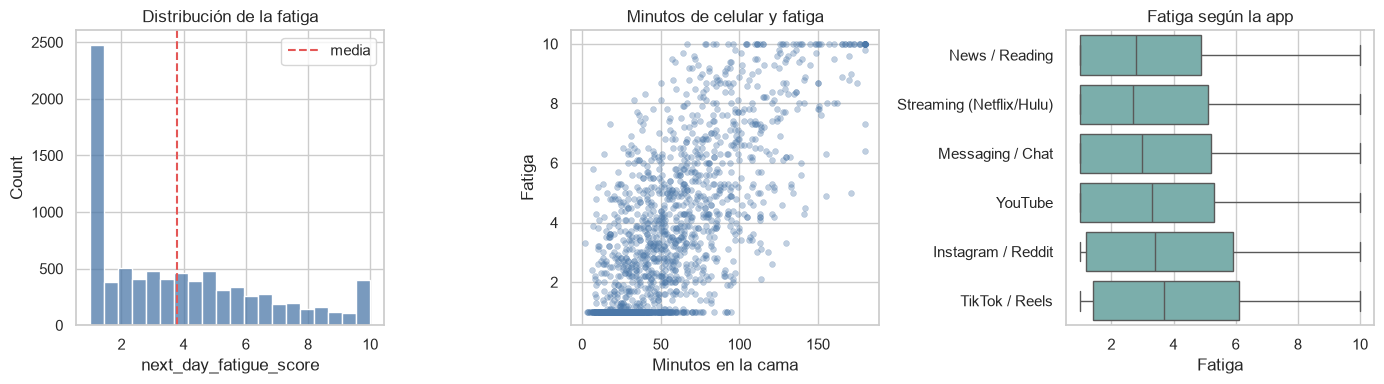

In [4]:
# Tres vistas del mismo patrón: forma de la fatiga, minutos de celular y tipo de app.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.histplot(df[objetivo], bins=20, ax=axes[0], color="#4C78A8")
axes[0].axvline(df[objetivo].mean(), color="#E45756", linestyle="--", label="media")
axes[0].set_title("Distribución de la fatiga")
axes[0].set_xlabel("next_day_fatigue_score")
axes[0].legend()

sns.scatterplot(
    data=df.sample(1500, random_state=42),
    x="bedtime_phone_minutes",
    y=objetivo,
    ax=axes[1],
    alpha=0.35,
    s=18,
    color="#4C78A8",
    edgecolor=None,
)
axes[1].set_title("Minutos de celular y fatiga")
axes[1].set_xlabel("Minutos en la cama")
axes[1].set_ylabel("Fatiga")

orden_apps = (
    df.groupby("primary_bedtime_app")[objetivo].mean().sort_values().index
)
sns.boxplot(
    data=df,
    y="primary_bedtime_app",
    x=objetivo,
    order=orden_apps,
    ax=axes[2],
    color="#72B7B2",
    fliersize=2,
)
axes[2].set_title("Fatiga según la app")
axes[2].set_xlabel("Fatiga")
axes[2].set_ylabel("")

fig.tight_layout()
plt.show()

El histograma confirma la asimetría: la barra más alta está pegada al 1. Por eso una métrica de porcentaje (MAPE) va a inflarse; un error de un punto pesa mucho cuando el valor real es 1.1.

El diagrama de puntos muestra una nube ascendente, con más dispersión cuando los minutos pasan de 80. El diagrama de cajas repite el orden de las medias por app y muestra que las cajas se traslapan: la app informa, pero no separa sola a quien amanece fatigado.

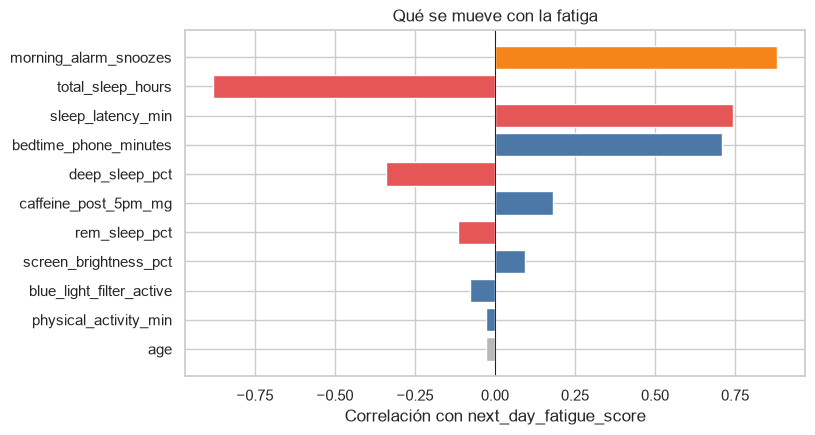

Fatiga media por cronotipo


,fatiga_media
chronotype,
Morning Lark,2.53
Intermediate,3.48
Night Owl,5.40


Fatiga media por ocupación


,fatiga_media
occupation_type,
Student,3.51
Remote Tech,3.54
Corporate 9-to-5,3.57
Freelance / Creative,3.68
Healthcare / Shift Worker,5.54


Brillo de pantalla × filtro de luz azul (fatiga media)


blue_light_filter_active,filtro apagado,filtro activo
screen_brightness_pct,,
"(9, 40]",3.63,3.24
"(40, 70]",3.98,3.65
"(70, 100]",4.38,3.74


In [5]:
# Compara correlaciones de conducta, contexto y fisiología con la fatiga.
# Sirve para ver la fuga: el sueño de esa noche predice la mañana, pero no es una entrada válida.
grupos = {
    "bedtime_phone_minutes": "conducta",
    "caffeine_post_5pm_mg": "conducta",
    "screen_brightness_pct": "conducta",
    "blue_light_filter_active": "conducta",
    "physical_activity_min": "conducta",
    "age": "contexto",
    "total_sleep_hours": "fisiológica",
    "sleep_latency_min": "fisiológica",
    "deep_sleep_pct": "fisiológica",
    "rem_sleep_pct": "fisiológica",
    "morning_alarm_snoozes": "mañana",
}
corr = df[list(grupos) + [objetivo]].corr(numeric_only=True)[objetivo].drop(objetivo)
corr = corr.reindex(corr.abs().sort_values(ascending=True).index)
colores = {
    "conducta": "#4C78A8",
    "contexto": "#B8B8B8",
    "fisiológica": "#E45756",
    "mañana": "#F58518",
}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(corr.index, corr.values, color=[colores[grupos[c]] for c in corr.index])
ax.axvline(0, color="black", linewidth=0.6)
ax.set_xlabel("Correlación con next_day_fatigue_score")
ax.set_title("Qué se mueve con la fatiga")
plt.show()

print("Fatiga media por cronotipo")
display(df.groupby("chronotype")[objetivo].mean().round(2).sort_values().to_frame("fatiga_media"))
print("Fatiga media por ocupación")
display(df.groupby("occupation_type")[objetivo].mean().round(2).sort_values().to_frame("fatiga_media"))
print("Brillo de pantalla × filtro de luz azul (fatiga media)")
brillo = pd.cut(df["screen_brightness_pct"], [9, 40, 70, 100])
display(
    df.pivot_table(objetivo, brillo, "blue_light_filter_active", observed=True)
    .round(2)
    .rename(columns={0: "filtro apagado", 1: "filtro activo"})
)

Las correlaciones rojas y naranja son altas: horas de sueño (−0.88), snoozes (0.88) y latencia (0.75). Usarlas para predecir la fatiga sería contestar con el resultado de la noche. El enunciado pide lo contrario: solo conducta. Esas columnas se quedan fuera.

Entre las conductuales, los minutos de celular dominan (0.71). Cafeína (0.18), brillo (0.09) y filtro (−0.08) aportan menos. La tabla de brillo × filtro muestra el mecanismo que describe el dataset: a más brillo, más fatiga, y el filtro baja un poco ese nivel en cada tramo. Es una interacción pequeña.

El cronotipo y el turno de trabajo también separan mucho (Night Owl 5.40 frente a Morning Lark 2.53; personal de salud en turnos 5.54 frente a cerca de 3.5 en el resto). Son contexto, no cafeína, app ni pantalla, así que tampoco entran. El modelo va a dejar esa señal afuera a propósito. Edad, género y minutos de ejercicio casi no cambian la fatiga media.

## 3. Limpieza de datos

Se revisan faltantes, duplicados, tipos y valores extremos. Cada hallazgo termina en una decisión: corregir, imputar, quitar o conservar.

In [6]:
# Revisa calidad: nulos, duplicados, rangos válidos y valores fuera del rango intercuartílico.
print("nulos por columna")
print(int(df.isna().sum().sum()))
print("filas duplicadas:", int(df.duplicated().sum()))
print("user_id duplicados:", int(df["user_id"].duplicated().sum()))

rangos = {
    "next_day_fatigue_score": (1, 10),
    "screen_brightness_pct": (10, 100),
    "blue_light_filter_active": (0, 1),
    "bedtime_phone_minutes": (0, None),
    "caffeine_post_5pm_mg": (0, None),
    "physical_activity_min": (0, None),
}
fuera_de_rango = {}
for col, (lo, hi) in rangos.items():
    mask = df[col] < lo
    if hi is not None:
        mask = mask | (df[col] > hi)
    fuera_de_rango[col] = int(mask.sum())
print("valores fuera del rango documentado:")
print(pd.Series(fuera_de_rango))

def contar_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((serie < lo) | (serie > hi)).sum()), round(lo, 1), round(hi, 1)

filas_iqr = []
for col in ["bedtime_phone_minutes", "caffeine_post_5pm_mg", "screen_brightness_pct", "physical_activity_min", objetivo]:
    n, lo, hi = contar_iqr(df[col])
    filas_iqr.append({
        "columna": col,
        "fuera_de_iqr": n,
        "pct": round(100 * n / len(df), 1),
        "limite_inferior": lo,
        "limite_superior": hi,
        "min": df[col].min(),
        "max": df[col].max(),
    })
print("Candidatos a outlier por IQR")
display(pd.DataFrame(filas_iqr))

nulos por columna
0
filas duplicadas: 0
user_id duplicados: 0
valores fuera del rango documentado:
next_day_fatigue_score      0
screen_brightness_pct       0
blue_light_filter_active    0
bedtime_phone_minutes       0
caffeine_post_5pm_mg        0
physical_activity_min       0
dtype: int64
Candidatos a outlier por IQR


,columna,fuera_de_iqr,pct,limite_inferior,limite_superior,min,max
0,bedtime_phone_minutes,237,2.8,-41.0,151.0,1.0,180.0
1,caffeine_post_5pm_mg,483,5.7,-82.5,137.5,0.0,250.0
2,screen_brightness_pct,0,0.0,1.5,109.5,10.0,100.0
3,physical_activity_min,40,0.5,-22.5,93.5,0.0,112.0
4,next_day_fatigue_score,0,0.0,-5.6,12.4,1.0,10.0


**Nulos.** Cero en las 18 columnas. No hay nada que imputar.

**Duplicados.** Cero filas repetidas y cero `user_id` repetidos. No se elimina nadie.

**Tipos.** Ya son correctos. No hace falta convertir el filtro ni las categorías.

**Rangos.** Fatiga entre 1 y 10, brillo entre 10 y 100, filtro en {0, 1}, minutos y miligramos en cero o más. No hay valores imposibles.

**Outliers de IQR.** Hay 237 filas (2.8%) con más de 151 minutos de celular, hasta 180, y 483 (5.7%) con más de 137 mg de cafeína, hasta 250. Esos topes caben en el dominio: tres horas de celular o alrededor de dos tazas y media no son errores de captura. El límite de IQR de la cafeína queda en negativo porque más de la mitad de la muestra está en cero; marcar esos 483 casos como error sería un artefacto de la regla, no un problema de calidad. **Se conservan.** Quitar la cola alta borraría justo los hábitos extremos que más deberían subir la fatiga.

La limpieza de este archivo es de validación, no de reparación. La tabla de modelado solo se queda con la objetivo y las cinco entradas de conducta que pide la pregunta.

## 4 a 7. Modelado, evaluación y registro en MLflow

Estas secciones se migraron a `train.py` para que el entrenamiento se repita desde la línea de comandos y cada corrida quede registrada en MLflow. Este notebook conserva solo la exploración de datos.

Lo que hace `train.py`:

- Construye la tabla de modelado con las cuatro variables de conducta y la app principal (`build_model_table`).
- Parte los datos 80/20 con semilla 42 (`split_data`).
- Entrena Ridge o XGBoost con validación cruzada de 5 pliegues y MAE como criterio (`build_pipeline`, `cross_validate_mae`).
- Calcula MAE, RMSE, MAPE y R² en prueba, y registra parámetros, métricas, artefactos y el modelo en MLflow (`evaluate`, `log_to_mlflow`).

```bash
python train.py
```
